In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:

df = pd.read_csv('../../data/spam.csv', encoding='latin-1')

df.head()


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
print(df.head())
print("\nNama kolom:", df.columns.tolist())


     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  

Nama kolom: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


In [4]:
# Dataset dengan format SMS Spam Collection
if 'v1' in df.columns and 'v2' in df.columns:
    df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})

# Dataset yang sebelumnya sudah memakai nama Labels dan SMS
df = df[['Labels', 'SMS']].dropna()

print(df.info())
print("\nJumlah label:")
print(df['Labels'].value_counts())


<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Labels  5572 non-null   str  
 1   SMS     5572 non-null   str  
dtypes: str(2)
memory usage: 541.4 KB
None

Jumlah label:
Labels
ham     4825
spam     747
Name: count, dtype: int64


In [5]:
X = df['SMS'].astype(str)
y = df['Labels'].astype(str)

print("Jumlah pesan:", len(X))
print("\nLabel:")
print(y.value_counts())


Jumlah pesan: 5572

Label:
Labels
ham     4825
spam     747
Name: count, dtype: int64


In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=50,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))


Jumlah data training: 4457
Jumlah data testing: 1115


In [7]:
bow = CountVectorizer(stop_words='english')

X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

print("Bentuk data training:", X_train_bow.shape)
print("Bentuk data testing:", X_test_bow.shape)
print("\nContoh fitur:")
print(bow.get_feature_names_out()[:20])


Bentuk data training: (4457, 7422)
Bentuk data testing: (1115, 7422)

Contoh fitur:
['00' '000' '000pes' '008704050406' '0089' '0121' '01223585236'
 '01223585334' '02' '0207' '02072069400' '02073162414' '02085076972' '021'
 '03' '04' '0430' '05' '050703' '0578']


In [8]:
mnb_bow = MultinomialNB()

mnb_bow.fit(X_train_bow, y_train)

y_pred_bow = mnb_bow.predict(X_test_bow)

print("Model CountVectorizer berhasil dilatih.")


Model CountVectorizer berhasil dilatih.


In [9]:
acc_bow = accuracy_score(y_test, y_pred_bow)

print("Akurasi CountVectorizer:", round(acc_bow * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_bow, zero_division=0))


Akurasi CountVectorizer: 98.21 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.91      0.93       149

    accuracy                           0.98      1115
   macro avg       0.97      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



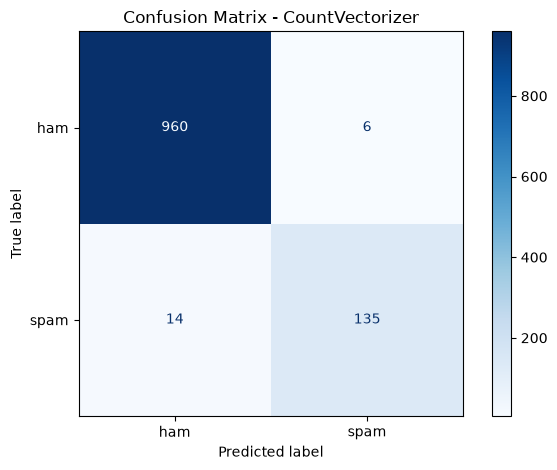

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_bow,
    labels=['ham', 'spam'],
    cmap='Blues'
)

plt.title('Confusion Matrix - CountVectorizer')
plt.tight_layout()
plt.show()


In [11]:
tfidf = TfidfVectorizer(stop_words='english')

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Bentuk data training:", X_train_tfidf.shape)
print("Bentuk data testing:", X_test_tfidf.shape)
print("\nContoh fitur:")
print(tfidf.get_feature_names_out()[:20])


Bentuk data training: (4457, 7422)
Bentuk data testing: (1115, 7422)

Contoh fitur:
['00' '000' '000pes' '008704050406' '0089' '0121' '01223585236'
 '01223585334' '02' '0207' '02072069400' '02073162414' '02085076972' '021'
 '03' '04' '0430' '05' '050703' '0578']


In [12]:
mnb_tfidf = MultinomialNB()

mnb_tfidf.fit(X_train_tfidf, y_train)

y_pred_tfidf = mnb_tfidf.predict(X_test_tfidf)

print("Model TF-IDF berhasil dilatih.")


Model TF-IDF berhasil dilatih.


In [13]:
acc_tfidf = accuracy_score(y_test, y_pred_tfidf)

print("Akurasi TF-IDF:", round(acc_tfidf * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tfidf, zero_division=0))

Akurasi TF-IDF: 97.31 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.80      0.89       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.94      1115
weighted avg       0.97      0.97      0.97      1115



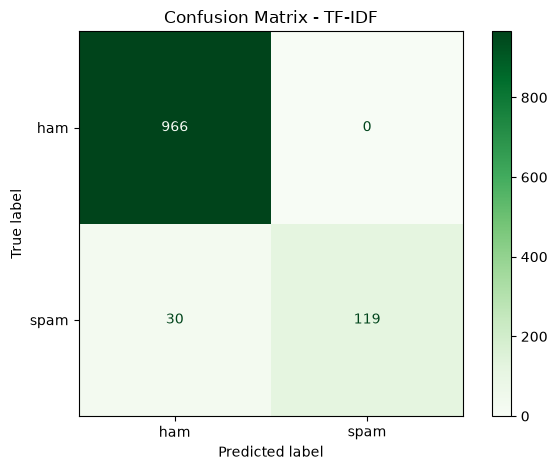

In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tfidf,
    labels=['ham', 'spam'],
    cmap='Greens'
)

plt.title('Confusion Matrix - TF-IDF')
plt.tight_layout()
plt.show()


In [15]:

from sklearn.metrics import precision_score, recall_score, f1_score

hasil_perbandingan = pd.DataFrame({
    'Metode': ['CountVectorizer', 'TF-IDF'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_bow),
        accuracy_score(y_test, y_pred_tfidf)
    ],
    'Precision Spam': [
        precision_score(y_test, y_pred_bow, pos_label='spam', zero_division=0),
        precision_score(y_test, y_pred_tfidf, pos_label='spam', zero_division=0)
    ],
    'Recall Spam': [
        recall_score(y_test, y_pred_bow, pos_label='spam', zero_division=0),
        recall_score(y_test, y_pred_tfidf, pos_label='spam', zero_division=0)
    ],
    'F1-Score Spam': [
        f1_score(y_test, y_pred_bow, pos_label='spam', zero_division=0),
        f1_score(y_test, y_pred_tfidf, pos_label='spam', zero_division=0)
    ]
})

print(hasil_perbandingan.round(4).to_string(index=False))


         Metode  Accuracy  Precision Spam  Recall Spam  F1-Score Spam
CountVectorizer    0.9821          0.9574       0.9060         0.9310
         TF-IDF    0.9731          1.0000       0.7987         0.8881


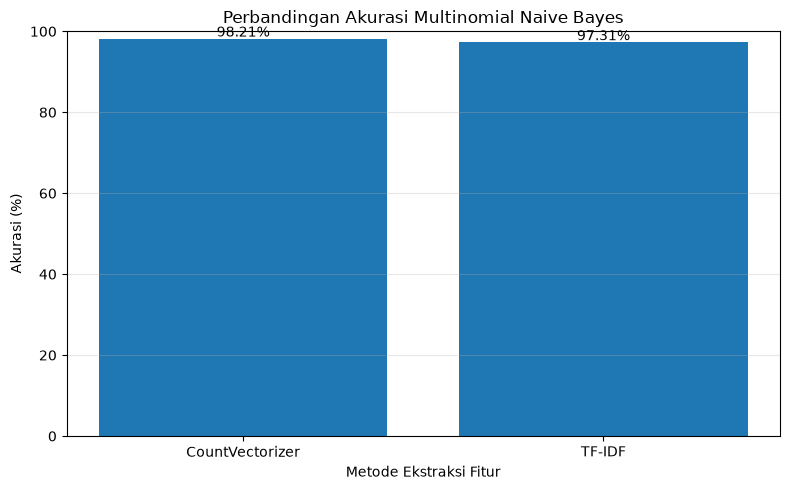

In [16]:

plt.figure(figsize=(8, 5))

plt.bar(
    hasil_perbandingan['Metode'],
    hasil_perbandingan['Accuracy'] * 100
)

plt.title('Perbandingan Akurasi Multinomial Naive Bayes')
plt.xlabel('Metode Ekstraksi Fitur')
plt.ylabel('Akurasi (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)

for i, nilai in enumerate(hasil_perbandingan['Accuracy']):
    plt.text(i, nilai * 100 + 0.5, f'{nilai * 100:.2f}%', ha='center')

plt.tight_layout()
plt.show()


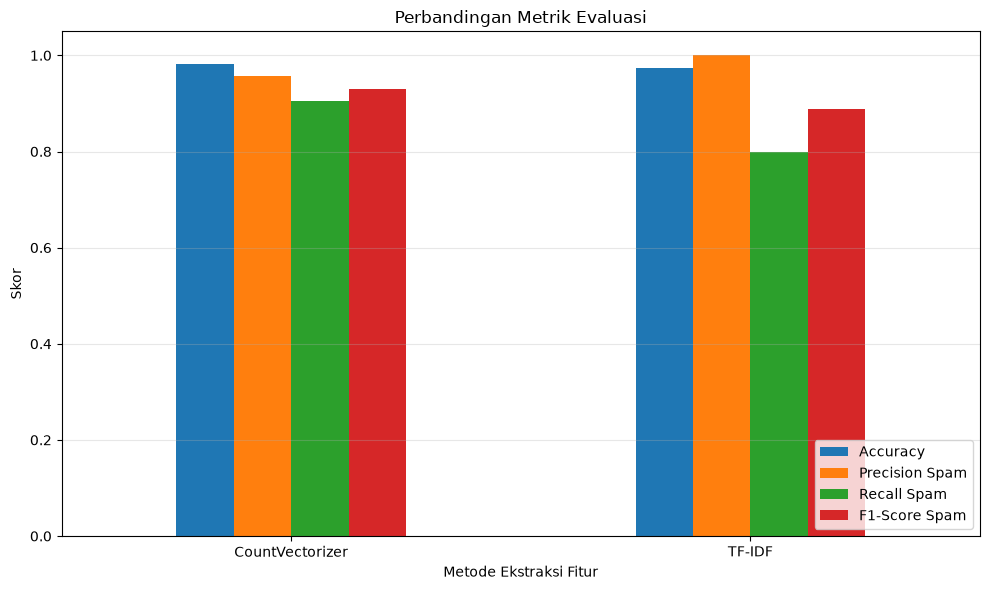

In [17]:

metrik = ['Accuracy', 'Precision Spam', 'Recall Spam', 'F1-Score Spam']

hasil_perbandingan.set_index('Metode')[metrik].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Perbandingan Metrik Evaluasi')
plt.xlabel('Metode Ekstraksi Fitur')
plt.ylabel('Skor')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [18]:

indeks_terbaik = hasil_perbandingan['F1-Score Spam'].idxmax()
metode_terbaik = hasil_perbandingan.loc[indeks_terbaik]

print("Metode terbaik berdasarkan F1-score spam:")
print(metode_terbaik['Metode'])
print("F1-score spam:", round(metode_terbaik['F1-Score Spam'], 4))
print("Akurasi:", round(metode_terbaik['Accuracy'] * 100, 2), "%")


Metode terbaik berdasarkan F1-score spam:
CountVectorizer
F1-score spam: 0.931
Akurasi: 98.21 %
